In [7]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import json

import astropy_healpix as ah
from astropy import units as u
from astropy.table import QTable
from astropy.coordinates import SkyCoord
from astropy.io import fits

import requests #for url downloading
from ligo.skymap.io.fits import read_sky_map

import mhealpy as mhp
import healpy as hp

In [3]:
#add path to our modules
sys.path.insert(1, '../')
from ic_visualization import plot_IC_alert
from params import p

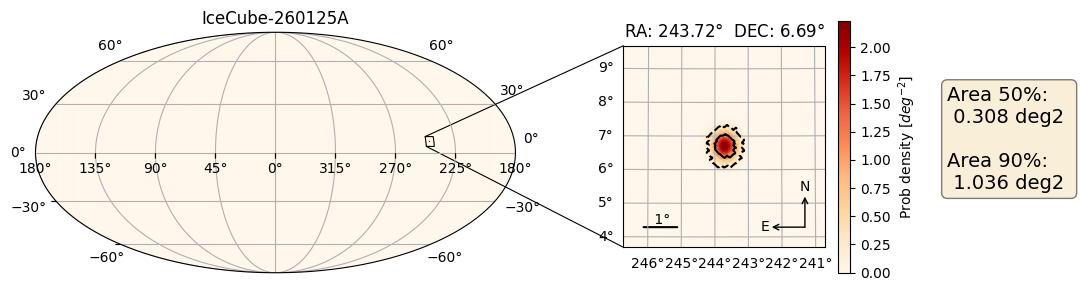

In [4]:
alert_str = '{"$schema": "https://gcn.nasa.gov/schema/v6.1.0/gcn/notices/icecube/single_neutrino_alerts.schema.json", "mission": "IceCube", "instrument": "IC86", "messenger": "Neutrino", "pipeline": "Bronze Track Alert", "record_number": 1, "event_name": ["IceCube-260125A"], "id": ["141985_63695019"], "alert_datetime": "2026-01-25T10:10:28.0Z", "alert_type": "update", "alert_tense": "current", "alert_topology": "Track", "number_of_events": 1, "ra": 243.72, "dec": 6.69, "ra_dec_error": "0.8", "containment_probability": 0.9, "systematic_included": true, "healpix_url": "https://roc-2.icecube.wisc.edu/public/alerts/IceCube-260125A_skymap_probdensity_multiorder.fits.gz", "trigger_time": "2026-01-25T10:09:39.883Z", "nu_energy": 159.06, "p_astro": 0.3924, "far": "6.263e-08"}'
alert = json.loads(alert_str)
map_path = plot_IC_alert(alert['healpix_url'], ra_dec_err=float(alert['ra_dec_error']))


In [5]:
# alert

In [6]:
skymap = QTable.read(map_path)

In [8]:
skymap.sort("PROBDENSITY", reverse=True)
level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
# Compute NSIDE for each pixel (vectorized)
nside = ah.level_to_nside(level)

# Pixel area for each pixel (astropy Quantity, in steradians)
pixel_area = ah.nside_to_pixel_area(nside)

# Convert probability density (per steradian) to probability per pixel.
# PROBDENSITY has units of sr⁻¹ → multiply by pixel area (sr) to get a pure number.
prob = pixel_area * skymap["PROBDENSITY"]

print(f"Total probability (should be ~1): {prob.sum():.4f}")

# Compute cumulative sum of probability after sorting.
# This gives the probability contained in the n-most-probable pixels.
cumprob = np.cumsum(prob)

# Locate the index where the cumulative probability reaches 50% and 90%.
# searchsorted gives the FIRST index where cumprob >= target.
i_50 = cumprob.searchsorted(0.5)
i_90 = cumprob.searchsorted(0.9)

print(f"\nPixel index at 50% cumulative probability: {i_50}")
print(f"Pixel index at 90% cumulative probability: {i_90}")


# Compute the AREA of the credible regions.
# Sum only the pixel areas up to the index where the cumulative probability crosses the threshold.
# Pixel areas are quantities in steradians → convert to deg².
area_50 = pixel_area[:i_50].sum()
area_50_deg2 = area_50.to(u.deg**2)

area_90 = pixel_area[:i_90].sum()
area_90_deg2 = area_90.to(u.deg**2)

print(f"\nArea of 50% credible region: {area_50_deg2:.3f}")
print(f"Area of 90% credible region: {area_90_deg2:.3f}")

Total probability (should be ~1): 1.0011

Pixel index at 50% cumulative probability: 88
Pixel index at 90% cumulative probability: 148

Area of 50% credible region: 0.308 deg2
Area of 90% credible region: 1.036 deg2


In [9]:
ah.healpix_to_lonlat(skymap['UNIQ'][i_50], nside[i_50])

(<Longitude 2.6473865 rad>, <Latitude -1.26420812 rad>)

In [10]:
help(ah)

Help on package astropy_healpix:

NAME
    astropy_healpix - BSD-licensed HEALPix for Astropy.

PACKAGE CONTENTS
    _core
    bench
    conftest
    core
    healpy
    high_level
    setup_package
    tests (package)
    utils
    version

VERSION
    1.1.2

FILE
    /Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/astropy_healpix/__init__.py




In [11]:
def plot_IC_alert(map_name, map_dir=p['map_dir'], coord='icrs', nest=True, plot_zoom_title=True, use_hpx_max=False, save_dir=p['save_dir'], show_fig=True,
                  print_radec_diff=False, map_from_url=True, hpx=None, header=None, use_own_hpx=False, normalize=True, title='',
                  ra_dec_err=None, plot_50=False, plot_90=False, plot_source=None):
    '''
    Docstring for plot_IC_alert
    
    Params:
    --------
    map_name: str, file name of map inside map_dir. It has to be a fits.gz file. 
    map_dir: path to directory that contains the probability maps. It can be set when calling the funciton or in 
        the params.py file
    coord: srt. Coordinate system:
        E -> Equatorial (ITRS)
        G -> Galactic
        icrs -> Celestial coordinates, Solar system, J2000
    plot_zoom_title: bool. If True, then shows the ra and dec where the zoom plot is centered. 
    use_hpx_max: bool. If True, then the center ra and dec of the zoom plot is calculated directly from the 
        probability map. If False, ra and dec are read from the header of the alert file. 
    save_dir: str. Path to directory where the plot should be saved. If save_dir='' or save_dir=False then the figure is not saved.
    show_fig: bool. Determines if the figure is shown with plt.show()
    print_radec_diff: bool. If true then both ra and dec methods of calculating are plotted, including the difference.
    map_from_url: bool. If True, map is downloaded directly from the url . If False, then asumes map is stored localy in map_dir

    Returns:
    title: str, alert name
    ra_diff, dec_diff: float. Difference in ra and dec between max pixel in healpix map and the header info. max_hpx - header 
        in degrees. 

    The maps need to be read with read_sky_map from ligo.skymap.io.fits, and not with healpy.read_map. Not sure why, but the healpy function
    can raise an IndexError. 
    '''

    #plotting info
    ligo_coord = {
        'E': 'geo',
        'icrs': 'astro',
        'G': 'galactic'
    }
    astropy_frame = {
        'icrs': 'icrs',
        'G': 'galactic'
    }
    
    if not use_own_hpx:
        #check if map_name is an url
        if 'https' in map_name:
            file_name = map_name.split('/')[-1]
            title = file_name.split('_')[0]

            #first we download the map
            response = requests.get(map_name)
            map_path = os.path.join(map_dir, file_name)
            with open(map_path, 'wb') as file: #also deletes previously existing file and redownloads alert. 
                file.write(response.content)
            try:
                hpx, header = read_sky_map(map_path, nest=nest)
            except ValueError as error:
                #It means that the header contains COORDSYS='c', and read_sky_map checks for COORDSYS == 'C'. 
                #we rewrite the header of the file and try again
                
                data, header = fits.getdata(map_path, header=True)
                if header['COORDSYS'] == 'c':
                    header['COORDSYS'] = 'C'
                    fits.writeto(map_path, data, header, overwrite=True)
                    #we try again
                    hpx, _ = read_sky_map(map_path, nest=nest)
                else:
                    raise ValuError(error)
        else:
            title = map_name.split('_')[0]
            data, header = fits.getdata(map_path, header=True)
            hpx, _ = read_sky_map(map_name, nest=nest)
    

    if normalize:
        hpx[hpx < 0] = 0
        hpx = hpx / np.sum(hpx)
    
    header_dict = dict(header)
    h_ra = header_dict['RA'] * u.deg
    h_dec = header_dict['DEC'] * u.deg

    if use_hpx_max:
        arg_max = np.argmax(hpx)
        ra, dec = hp.pix2ang(header_dict['NSIDE'], arg_max, lonlat=True, nest=True)
        ra = ra * u.deg
        dec = dec * u.deg
    else:
        ra = h_ra
        dec = h_dec

    center = SkyCoord(ra.to('rad'), dec.to('rad'), frame=astropy_frame[coord])
    
    fig = plt.figure(figsize=(6, 6), dpi=100)
    
    ax = plt.axes(
        [0.05, 0.05, 0.8, 0.9],
        projection=f'{ligo_coord[coord]} degrees mollweide',
        center=SkyCoord(0 * u.rad, 0 * u.rad, frame=astropy_frame[coord]))
    
    ax_inset = plt.axes(
        [1.03, 0.3, 0.42, 0.42],
        projection=f'{ligo_coord[coord]} degrees zoom',
        center=center,
        radius=3*u.deg)


    if coord == 'icrs':
        for key in ['ra', 'dec']:
            # ax_inset.coords[key].set_ticklabel_visible(False)
            ax_inset.coords[key].set_ticks_visible(False)
        
    ax_inset.set_xlabel("")
    ax_inset.set_ylabel("")
    ax.grid()
    ax.locator_params(nbins=10) #test!
    ax.mark_inset_axes(ax_inset)
    ax.connect_inset_axes(ax_inset, 'upper left')
    ax.connect_inset_axes(ax_inset, 'lower left')
    ax_inset.scalebar((0.1, 0.1), 1 * u.deg).label()
    ax_inset.compass(0.9, 0.1, 0.2)
    ax_inset.grid()


    skymap = QTable.read(map_path)
    level, ipix = ah.uniq_to_level_ipix(skymap['UNIQ'])
    nside = ah.level_to_nside(level)
    # match_ipix = ah.lonlat_to_healpix(ra, dec, nside, order='nested') #for prob at a specific location
    # match_index = np.flatnonzero(ipix == match_ipix)[0]
    prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)

    m = mhp.HealpixMap(data=prob_density, uniq=skymap['UNIQ'], density=True)
    img = m.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
    ax.imshow(img, cmap='OrRd')
    if not plot_90 and not plot_50:
        img_inset = m.get_wcs_img(ax_inset)
        im = ax_inset.imshow(img_inset, cmap='OrRd')
        c = plt.colorbar(im, label=r'Prob density [$deg^{-2}$]')
        

    # ax_inset.errorbar(
    #     center.ra.deg, center.dec.deg,
    #     transform=ax_inset.get_transform('world'),
    #     marker='o',
    #     markersize=5,
    #     yerr=ra_dec_err,
    #     xerr=ra_dec_err)
    ax.set_title(title)

    # plot header re/dec
    
    h_center = SkyCoord(h_ra.to('rad'), h_dec.to('rad'), frame=astropy_frame[coord])


    #90 % region
    skymap.sort("PROBDENSITY", reverse=True)
    level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
    nside = ah.level_to_nside(level)
    pixel_area = ah.nside_to_pixel_area(nside)
    prob = pixel_area * skymap["PROBDENSITY"]
    cumprob = np.cumsum(prob)
    # searchsorted gives the FIRST index where cumprob >= target.
    i_50 = cumprob.searchsorted(0.5)
    i_90 = cumprob.searchsorted(0.9)
    
    m_prob = mhp.HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
    img = m_prob.get_wcs_img(ax_inset)#, coord = coord, rasterize = rasterize)
    im = ax_inset.contour(img, levels=[0.5, 0.9], colors=['black', 'black'], linestyles=['solid', 'dashed'], label='50%/90%') #nested=True,
    # c = plt.colorbar(im, label=r'Cum prob [$deg^{-2}$]')

    area_50 = pixel_area[:i_50].sum()
    area_50_deg2 = area_50.to(u.deg**2)

    area_90 = pixel_area[:i_90].sum()
    area_90_deg2 = area_90.to(u.deg**2)

    #area text
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    text_str = f'Area 50%:\n {area_50_deg2:.3f} \n\nArea 90%:\n {area_90_deg2:.3f}'
    ax.text(1.9, 0.35, text_str, fontsize=14, bbox=props, transform=ax.transAxes)#, horizontalalignment='right', va='top')
    
    
    if plot_90 or plot_50:
        ra_sel = []
        dec_sel = []
        if plot_90:
            max_indx = i_90
            label = '90%'
        elif plot_50:
            max_indx = i_50
            label = '50%'
        for hp_index in range(max_indx+1):
            uniq = skymap[hp_index]['UNIQ']
            level, ipix = ah.uniq_to_level_ipix(uniq)
            nside = ah.level_to_nside(level)
            ra_i, dec_i = ah.healpix_to_lonlat(ipix, nside, order='nested')
            ra_i = ra_i.to('deg') / u.deg
            dec_i = dec_i.to('deg') / u.deg
            
            ra_sel.append(ra_i)
            dec_sel.append(dec_i)
        ax_inset.scatter(ra_sel, dec_sel, c='cyan', transform=ax_inset.get_transform('world'), label=label, alpha=0.5, s=5)

    
    #plot a candidate source
    if plot_source:
        ax_inset.plot(plot_source['ra'],
                      plot_source['dec'], 'o',
                      label=plot_source['name'],
                      c='cyan',  transform=ax_inset.get_transform('world'))    
    
    #plot params    
    
    ax_inset.legend(framealpha=1)
    if plot_zoom_title:
        ra_title = ra / u.deg
        dec_title = dec / u.deg
        ax_inset.set_title(fr'RA: {ra_title:.2f}$\degree$  DEC: {dec_title:.2f}$\degree$')
    if save_dir:
        plt.savefig(os.path.join(save_dir, f'{title}_mw_zoom.png'), bbox_inches='tight')
    if show_fig:
        plt.show()
    

    return map_path

In [12]:
source = {'ra': 145.57604250,
        'dec': 13.02393920,
        'name': 'ZTF26aabnqai'
}

/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/astropy/visualization/wcsaxes/core.py:248: UserWarning: The following kwargs were not used by contour: 'label'
  cset = super().contour(*args, **kwargs)


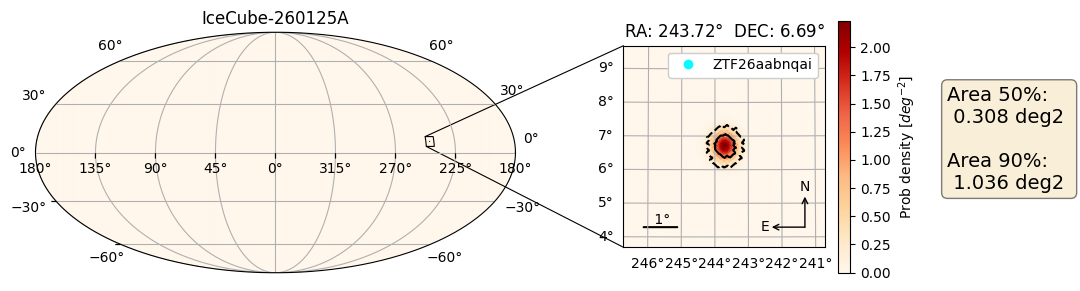

In [13]:

map_path = plot_IC_alert(alert['healpix_url'], ra_dec_err=float(alert['ra_dec_error']), plot_90=False, plot_source=source)
# map_path = plot_IC_alert(alert['healpix_url'], ra_dec_err=float(alert['ra_dec_error']), plot_50=True)

In [30]:
data, header = fits.getdata(map_path, header=True)
header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   16 / length of dimension 1                          
NAXIS2  =                 5166 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                    2 / number of table fields                         
TTYPE1  = 'UNIQ    '                                                            
TFORM1  = 'K       '                                                            
TTYPE2  = 'PROBDENSITY'                                                         
TFORM2  = 'D       '                                                            
TUNIT2  = 'sr-1    '        

/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/astropy/visualization/wcsaxes/core.py:248: UserWarning: The following kwargs were not used by contour: 'label'
  cset = super().contour(*args, **kwargs)


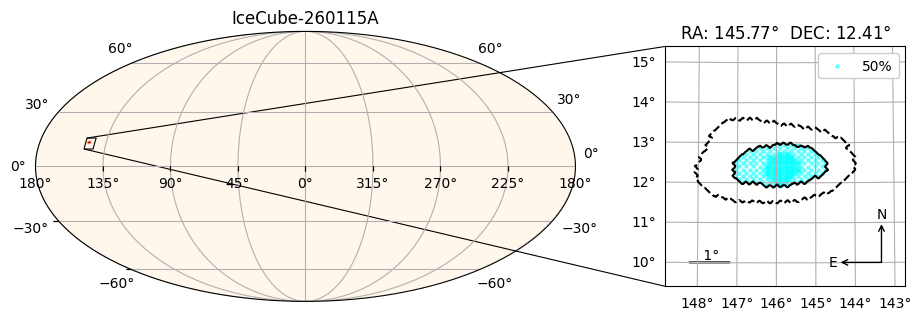

In [12]:
map_path = plot_IC_alert(alert['healpix_url'], ra_dec_err=float(alert['ra_dec_error']), plot_50=True)

/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/astropy/visualization/wcsaxes/core.py:248: UserWarning: The following kwargs were not used by contour: 'label'
  cset = super().contour(*args, **kwargs)


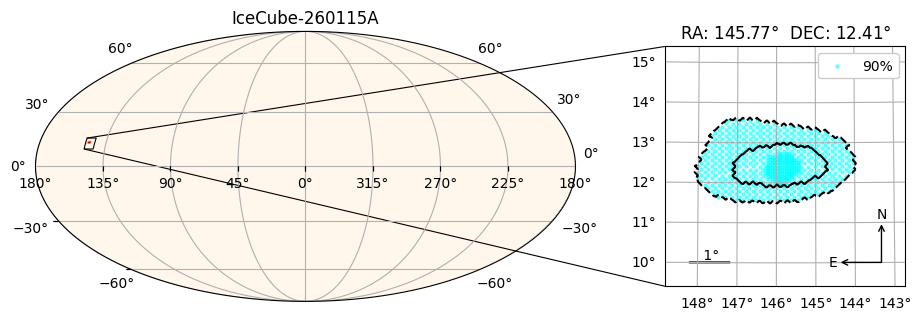

In [13]:
map_path = plot_IC_alert(alert['healpix_url'], ra_dec_err=float(alert['ra_dec_error']), plot_90=True)

In [14]:
skymap = QTable.read(map_path)
level, ipix = ah.uniq_to_level_ipix(skymap['UNIQ'])
nside = ah.level_to_nside(level)
# match_ipix = ah.lonlat_to_healpix(ra, dec, nside, order='nested')
# match_index = np.flatnonzero(ipix == match_ipix)[0]
prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)


In [15]:
skymap.sort("PROBDENSITY", reverse=True)
level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
nside = ah.level_to_nside(level)
pixel_area = ah.nside_to_pixel_area(nside)
prob = pixel_area * skymap["PROBDENSITY"]
cumprob = np.cumsum(prob)
# searchsorted gives the FIRST index where cumprob >= target.
i_50 = cumprob.searchsorted(0.5)
i_90 = cumprob.searchsorted(0.9)
    

In [16]:
len_data_points = len(skymap['UNIQ'])
all_ra = []
all_dec = []
in_90 = np.zeros((len_data_points, len_data_points))
in_50 = np.zeros((len_data_points, len_data_points))
for hp_index in range(len_data_points):
    uniq = skymap[hp_index]['UNIQ']
    level, ipix = ah.uniq_to_level_ipix(uniq)
    nside = ah.level_to_nside(level)
    ra_i, dec_i = ah.healpix_to_lonlat(ipix, nside, order='nested')
    ra_i = ra_i.to('deg') / u.deg
    dec_i = dec_i.to('deg') / u.deg

    all_ra.append(float(ra_i))
    all_dec.append(float(dec_i))
ra_90, dec_90 = all_ra[:i_90], all_dec[:i_90]
ra_50, dec_50 = all_ra[:i_50], all_dec[:i_50]


Z_90 = np.ones((len(ra_90), len(dec_90))) * 90
Z_50 = np.ones((len(ra_50), len(dec_50))) * 50
    

    

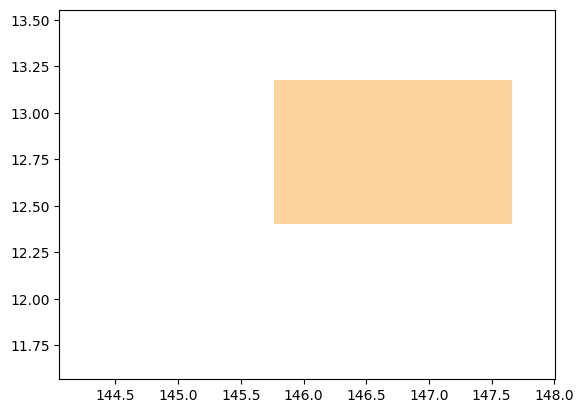

In [17]:
plt.contourf(ra_90, dec_90, Z_90, cmap='OrRd')
plt.show()